# Phase 3: Holling type II feeding

Phase 2 added logistic algae growth and natural shrimp mortality. Here we keep both changes and let feeding saturate at high food abundance, for both shrimp eating algae and birds eating shrimp.

**Question:** How does feeding saturation change coexistence and oscillations?

Run cells in order. Edit the parameter cell and rerun all cells to experiment. Parameters are illustrative, not calibrated; time is measured in days and algae is measured in micrograms chlorophyll-a/L, shrimp in individuals/L, and birds in individuals. This notebook does not change or export files from earlier phases.

## Equations

Define the consumption rate per consumer:

$$
f_A(A)=\frac{C_A A}{1+h_A C_A A}
$$

$$
f_S(S)=\frac{C_S S}{1+h_S C_S S}.
$$

Then, in state order $(S,A,B)$,

$$
\frac{dS}{dt}=\gamma_S S f_A(A)-B f_S(S)-\delta_S S
$$

$$
\frac{dA}{dt}=\beta_A A(1-A/K)-S f_A(A)
$$

$$
\frac{dB}{dt}=\gamma_B B f_S(S)-\delta_B B.
$$

$h_A$ is the handling time per algae consumed by shrimp, and $h_S$ is the handling time per shrimp consumed by birds. Positive handling times limit per-consumer feeding rates to $1/h_A$ and $1/h_S$. Setting both handling times to zero recovers Phase 2 exactly. Set only one to zero to isolate the other feeding change.

## Species, units, and parameter evidence

For this school exploration, the algae state $A$ is **water-column chlorophyll-a concentration**, used directly as a proxy for algae abundance. Its units are **micrograms of chlorophyll-a per liter** ($\mu$g Chl-a/L). It is not total algal dry mass or carbon. Water chlorophyll includes multiple phytoplankton species; treating it as the food available to shrimp is a simplifying assumption.

*Dunaliella viridis* remains the focal algae species motivating the model. [Utah DWR, Algae and algal blooms](https://wildlife.utah.gov/gslep/wildlife/algae) identifies it as a preferred food of brine shrimp. The chlorophyll proxy is not a species-specific measurement of *D. viridis*.

### Sources for chlorophyll, salinity, and shrimp observations

- [Belovsky et al. (2025), Environment and phytoplankton relative abundances in a hypersaline lake: 27 years in Great Salt Lake, USA and experiments](https://link.springer.com/article/10.1007/s10452-025-10190-1): a source for chlorophyll-a measurements, salinity information, and experiments with *D. viridis*. Laboratory chlorophyll is measured in micrograms Chl-a/L. Experimental salinities are 30, 60, 90, 120, and 150 **ppt** (parts per thousand); these are experimental treatments, not a chosen present-day lake salinity. The study also analyzes South Arm field monitoring from 1994-2020. Its experimental absolute growth measure is not directly the per-capita `beta_A` in our equations.
- [Utah DWQ Great Salt Lake Data Explorer](https://udwq.shinyapps.io/GSL_data_explorer/): a place to look for lake chlorophyll-a and salinity observations. [DWQ monitoring documentation](https://lf-public.deq.utah.gov/WebLink/ElectronicFile.aspx?dbid=0&docid=14163&eqdocs=DWQ-2021-018149&repo=Public) describes these parameters. Check the downloaded record's units, date, location, depth, and method; the dashboard was not directly inspected. Do not interchange ppt and g/L without checking the reported salinity definition and brine density.
- [Utah DWR brine shrimp sampling reports](https://wildlife.utah.gov/gslep/harvest): observations **per liter of lake water**, separated by life stage and sex. Use the appropriate live-shrimp categories for $S$ and avoid double-counting female subcategories. Cysts are separate from live shrimp.

### Chosen state units

Time is measured in **days**. Shrimp is measured as **density (individual shrimp/L)** to match the sampling reports and the concentration basis of algae. Birds remain **individual birds** in the modeled region. Population observations must describe compatible dates and habitat. The remaining bird species, shrimp life stages, season, and region are choices to make before calibration.

| Quantity | Meaning | Unit / status |
|---|---|---|
| $t$ | Elapsed time | days |
| $A$ | Water chlorophyll-a, a proxy for algae | $\mu$g Chl-a/L |
| $S$ | Live brine shrimp density | individual shrimp/L |
| $B$ | Bird abundance in the modeled region | individual birds |
| $A_0,S_0,B_0$ | Initial observations | Same units as the corresponding states |
| $T$ | Simulation duration | days |
| Salinity (not yet a model state or parameter) | Environmental context | Study experiments: ppt; retain units specified by each field dataset |

### Parameter table

The units below follow from the current equations with these state units. Default values are shared by Phases 2 and 3; handling times apply only to Phase 3. **All existing numbers remain illustrative and uncalibrated under the chosen units.** Relabeling the states does not convert or validate the old numerical values.

| Code parameter | Meaning | Required units | Illustrative default | Evidence to seek |
|---|---|---|---|---|
| `beta_A` | Maximum per-capita algae growth rate | day$^{-1}$ | 1.0 | Fit growth curves under relevant environmental conditions |
| `K` | Chlorophyll carrying capacity without grazing | $\mu$g Chl-a/L | 10.0 | Ungrazed experiments or constrained estimates; grazed maxima need not equal `K` |
| `C_A` | Shrimp-algae feeding coefficient | L/(shrimp day) | 0.5 | Per-shrimp chlorophyll removal versus food concentration |
| `C_S` | Effective bird-shrimp feeding coefficient | 1/(bird day) | 0.4 | Bird feeding and habitat volume conversions |
| `gamma_S` | Shrimp density gain per chlorophyll concentration loss | shrimp/($\mu$g Chl-a) | 0.2 | Shrimp production versus chlorophyll removal |
| `gamma_B` | Bird count gain per shrimp density loss | bird L/shrimp | 0.3 | Demographic evidence and volume conversion; review migration assumptions |
| `delta_S` | Shrimp natural per-capita mortality | day$^{-1}$ | 0.1 | Stage-specific survival, separated from predation |
| `delta_B` | Bird natural per-capita mortality | day$^{-1}$ | 0.12 | Survival, separated from migration departures |
| `h_A` | Inverse maximum per-shrimp chlorophyll consumption rate | day shrimp/($\mu$g Chl-a) | 0.5 | Saturating shrimp feeding curve |
| `h_S` | Inverse maximum per-bird shrimp density removal rate | day bird L/shrimp | 0.5 | Saturating bird feeding curve and habitat volume conversion |

`gamma_S` and `gamma_B` are unit-dependent conversion factors, not necessarily dimensionless efficiencies or bounded by one. Chlorophyll-based conversions are effective model relationships rather than direct food-mass efficiencies.

Because birds are counts and shrimp is density, the bird predation terms still require a defined habitat volume when translating physical consumption into model coefficients. For a fixed volume $V$ in liters, total bird consumption $Q$ shrimp/day removes density at $Q/V$ shrimp/L/day. Thus `C_S`, `gamma_B`, and `h_S` include spatial conversions. Retaining the current equations is acceptable for exploration with effective coefficients, but a changing-volume model would require an explicit mass balance.

Next steps: select compatible lake observations, document their region, season, depths, and units, then estimate daily parameter ranges with sources and uncertainty. Salinity is recorded as context for now; the current equations do not yet depend on it.


In [1]:
from dataclasses import dataclass, replace
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

@dataclass(frozen=True)
class Parameters:
    beta_A: float = 1.0
    C_A: float = 0.5
    C_S: float = 0.4
    gamma_S: float = 0.2
    gamma_B: float = 0.3
    delta_B: float = 0.12
    K: float = 10.0
    delta_S: float = 0.1
    h_A: float = 0.5  # New: shrimp handling time per algae
    h_S: float = 0.5  # New: bird handling time per shrimp

p = Parameters()
y0 = np.array([1.0, 6.0, 0.5])  # Shrimp, algae, birds
T = 600.0
print(p)

Parameters(beta_A=1.0, C_A=0.5, C_S=0.4, gamma_S=0.2, gamma_B=0.3, delta_B=0.12, K=10.0, delta_S=0.1, h_A=0.5, h_S=0.5)


In [2]:
def feeding(food, attack, handling):
    return attack*food/(1 + handling*attack*food)

def rhs(t, state, p):
    S, A, B = state
    algae_eaten = S*feeding(A, p.C_A, p.h_A)
    shrimp_eaten = B*feeding(S, p.C_S, p.h_S)
    return np.array([
        p.gamma_S*algae_eaten - shrimp_eaten - p.delta_S*S,
        p.beta_A*A*(1 - A/p.K) - algae_eaten,
        p.gamma_B*shrimp_eaten - p.delta_B*B,
    ])

def simulate(p, initial=None, duration=None):
    if initial is None: initial = y0
    if duration is None: duration = T
    for name, value in vars(p).items():
        if not np.isfinite(value) or (value < 0 if name in ('h_A', 'h_S') else value <= 0):
            raise ValueError('Use positive parameters and nonnegative handling times.')
    initial = np.asarray(initial, dtype=float)
    if initial.shape != (3,) or not np.all(np.isfinite(initial)) or np.any(initial < 0):
        raise ValueError('Use three finite, nonnegative initial populations.')
    if not np.isfinite(duration) or duration <= 0:
        raise ValueError('Duration must be positive and finite.')
    sol = solve_ivp(lambda t, y: rhs(t, y, p), (0, duration), initial,
                    t_eval=np.linspace(0, duration, 3001), rtol=1e-8, atol=1e-10)
    if not sol.success: raise RuntimeError(sol.message)
    if np.min(sol.y) < -1e-7: raise RuntimeError('Inspect numerical negative populations.')
    return sol

sol = simulate(p)

## Feeding saturation and comparison with Phase 2

The dashed curves use zero handling times. Solid curves show feeding with the current handling times. Each rate is per consumer, so total consumption also depends on the number of consumers.

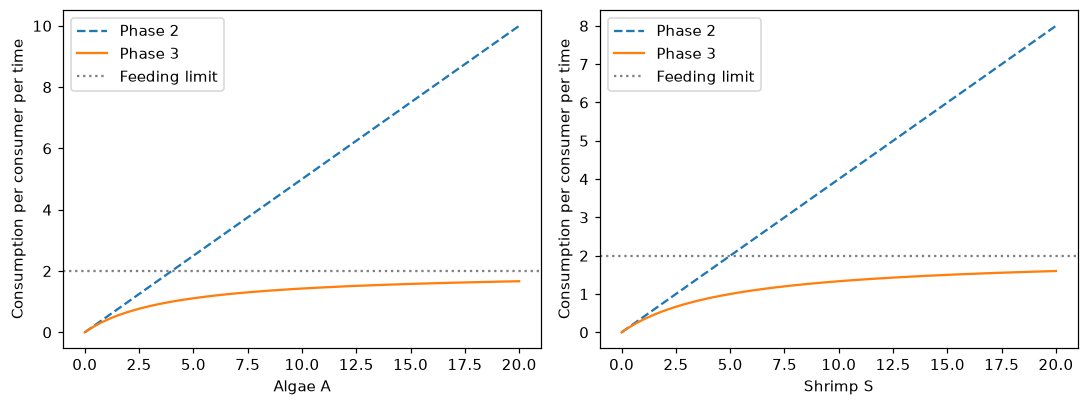

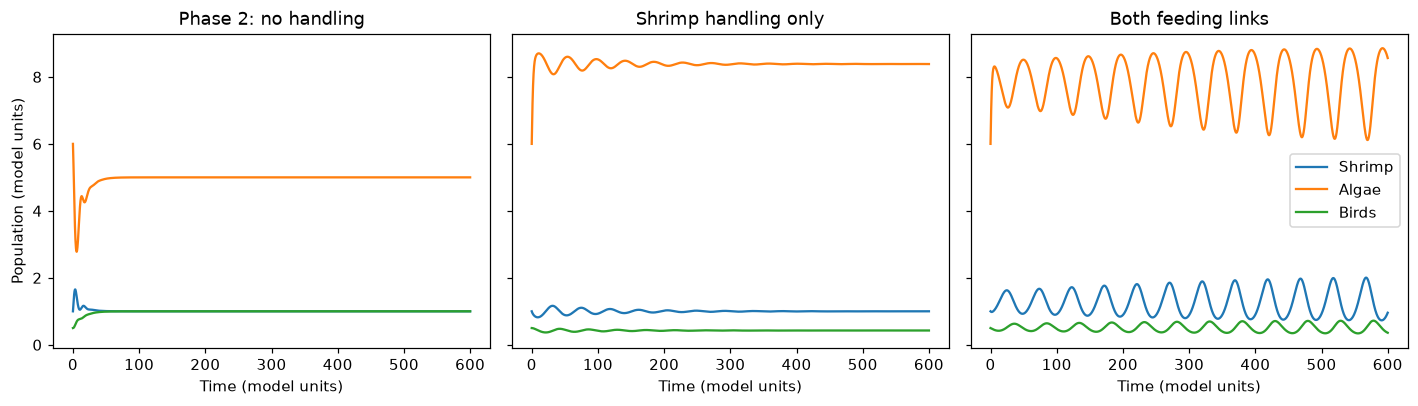

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, attack, handling, food_name in zip(axes, [p.C_A, p.C_S], [p.h_A, p.h_S], ['Algae A', 'Shrimp S']):
    food = np.linspace(0, 20, 300)
    ax.plot(food, feeding(food, attack, 0), '--', label='Phase 2')
    ax.plot(food, feeding(food, attack, handling), label='Phase 3')
    if handling > 0: ax.axhline(1/handling, color='gray', linestyle=':', label='Feeding limit')
    ax.set(xlabel=food_name, ylabel='Consumption per consumer per time')
    ax.legend()
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True, sharey=True)
trials = [('Phase 2: no handling', replace(p, h_A=0, h_S=0)),
          ('Shrimp handling only', replace(p, h_S=0)), ('Both feeding links', p)]
for ax, (title, trial) in zip(axes, trials):
    result = simulate(trial)
    for i, label in enumerate(['Shrimp', 'Algae', 'Birds']):
        ax.plot(result.t, result.y[i], label=label)
    ax.set(title=title, xlabel='Time (days)')
axes[0].set_ylabel('Population (model units)')
axes[-1].legend()
fig.tight_layout()
plt.show()

## Coexistence candidates and local stability

Bird equilibrium requires

$$
S^*=\frac{\delta_B}{C_S(\gamma_B-\delta_B h_S)}.
$$

This requires $\gamma_B>\delta_B h_S$: otherwise bird reproduction cannot exceed mortality even at arbitrarily high shrimp abundance. For this $S^*$, solve the algae equilibrium condition

$$
\beta_A(1-A^*/K)(1+h_A C_A A^*)=C_A S^*.
$$

Unlike Phase 2, this can give more than one algae candidate. For every real root with $0<A^*<K$, compute

$$
B^*=\frac{S^*(\gamma_S f_A(A^*)-\delta_S)}{f_S(S^*)}.
$$

Keep only strictly positive populations. The next cell checks each candidate's equation residual and Jacobian eigenvalues. Negative real parts indicate local stability; a positive real part indicates instability. Near-zero real parts need further analysis. A finite simulation alone does not establish a stable cycle or global convergence.

In [4]:
def coexistence_candidates(p):
    if p.gamma_B <= p.delta_B*p.h_S: return []
    S = p.delta_B/(p.C_S*(p.gamma_B-p.delta_B*p.h_S))
    q = p.h_A*p.C_A
    coefficients = [q, 1-q*p.K, p.K*(p.C_A*S/p.beta_A-1)] if q > 0 else [1, p.K*(p.C_A*S/p.beta_A-1)]
    candidates = []
    for root in np.roots(coefficients):
        if abs(root.imag) > 1e-8: continue
        A = root.real
        if not 0 < A < p.K: continue
        B = S*(p.gamma_S*feeding(A, p.C_A, p.h_A)-p.delta_S)/feeding(S, p.C_S, p.h_S)
        if B > 0: candidates.append(np.array([S, A, B]))
    return candidates

def jacobian(state, p):
    S, A, B = state
    fA = feeding(A, p.C_A, p.h_A)
    fS = feeding(S, p.C_S, p.h_S)
    dfA = p.C_A/(1+p.h_A*p.C_A*A)**2
    dfS = p.C_S/(1+p.h_S*p.C_S*S)**2
    return np.array([
        [p.gamma_S*fA-B*dfS-p.delta_S, p.gamma_S*S*dfA, -fS],
        [-fA, p.beta_A*(1-2*A/p.K)-S*dfA, 0],
        [p.gamma_B*B*dfS, 0, p.gamma_B*fS-p.delta_B],
    ])

for title, trial in trials:
    candidates = coexistence_candidates(trial)
    print(title)
    if not candidates: print('  No strictly positive coexistence candidate.')
    for equilibrium in candidates:
        residual = np.linalg.norm(rhs(0, equilibrium, trial), ord=np.inf)
        assert residual < 1e-8
        eigenvalues = np.linalg.eigvals(jacobian(equilibrium, trial))
        real = eigenvalues.real
        stability = 'locally stable' if np.all(real < -1e-8) else ('unstable' if np.any(real > 1e-8) else 'needs further analysis')
        print('  [S, A, B] =', np.round(equilibrium, 5))
        print('  Eigenvalues:', eigenvalues)
        print('  Stability:', stability)

Phase 2: no handling
  [S, A, B] = [1. 5. 1.]
  Eigenvalues: [-0.20391936+0.46779264j -0.20391936-0.46779264j -0.09216128+0.j        ]
  Stability: locally stable
Shrimp handling only
  [S, A, B] = [1.      8.38516 0.42703]
  Eigenvalues: [-0.71007301+0.j         -0.0095569 +0.14476879j -0.0095569 -0.14476879j]
  Stability: locally stable
Both feeding links
  [S, A, B] = [1.25    7.89898 0.5173 ]
  Eigenvalues: [-0.62290628+0.j          0.00279436+0.12878492j  0.00279436-0.12878492j]
  Stability: unstable


## Shrimp-algae phase portrait without birds

With $B=0$, the nonzero nullclines are

$$
A=\frac{\delta_S}{C_A(\gamma_S-\delta_S h_A)}
$$

and

$$
S=\frac{\beta_A}{C_A}(1-A/K)(1+h_A C_A A).
$$

The first requires $\gamma_S>\delta_S h_A$. If its algae level is at or above $K$, there is no positive bird-free shrimp-algae equilibrium. The portrait below describes only the bird-free subsystem.

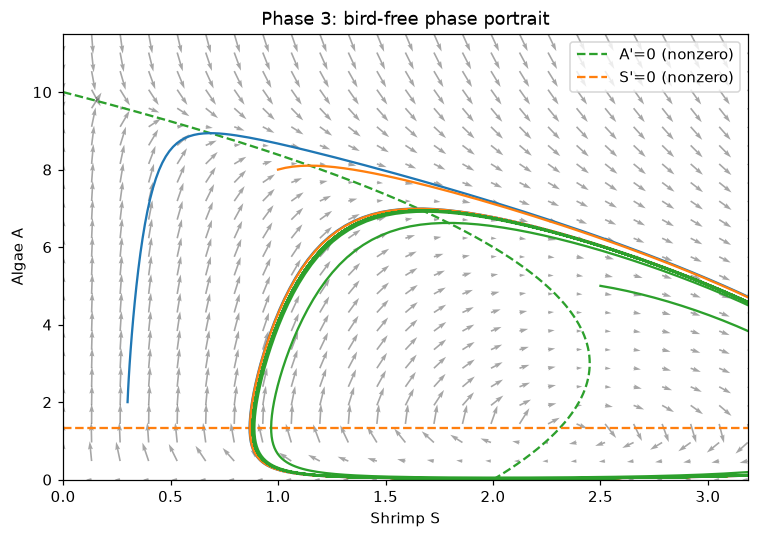

In [5]:
a_line = np.linspace(0, p.K, 300)
s_line = p.beta_A/p.C_A*(1-a_line/p.K)*(1+p.h_A*p.C_A*a_line)
Smax = max(3.0, 1.3*np.max(s_line))
Amax = 1.15*p.K
SS, AA = np.meshgrid(np.linspace(0, Smax, 25), np.linspace(0, Amax, 25))
dS = SS*(p.gamma_S*feeding(AA, p.C_A, p.h_A)-p.delta_S)
dA = p.beta_A*AA*(1-AA/p.K)-SS*feeding(AA, p.C_A, p.h_A)
speed = np.maximum(np.hypot(dS/Smax, dA/Amax), 1e-12)
fig, ax = plt.subplots(figsize=(7, 5))
ax.quiver(SS, AA, dS/speed, dA/speed, alpha=0.35, angles='xy')
ax.plot(s_line, a_line, '--', color='tab:green', label="A'=0 (nonzero)")
if p.gamma_S > p.delta_S*p.h_A:
    Astar = p.delta_S/(p.C_A*(p.gamma_S-p.delta_S*p.h_A))
    if Astar < Amax: ax.axhline(Astar, linestyle='--', color='tab:orange', label="S'=0 (nonzero)")
for initial in ([0.3, 2, 0], [1.0, 8, 0], [2.5, 5, 0]):
    trajectory = simulate(p, initial)
    ax.plot(trajectory.y[0], trajectory.y[1])
ax.set(xlim=(0, Smax), ylim=(0, Amax), xlabel='Shrimp S', ylabel='Algae A', title='Phase 3: bird-free phase portrait')
ax.legend()
fig.tight_layout()
plt.show()

## Next experiments

- Set `h_A = h_S = 0` to recover Phase 2.
- Change one handling time at a time and compare the feeding curves and time series.
- Vary `K` and check how equilibrium stability changes.
- Repeat with different initial populations and longer time horizons before drawing conclusions about oscillations.

Handling times and other parameters still need observational estimates in the units specified above before ecological interpretation.